In [1]:
%cd ../
# Import required libraries 
from pathlib import Path
import hydra
from omegaconf import DictConfig, OmegaConf, open_dict
from hydra.core.global_hydra import GlobalHydra
import torch
import json, time, shutil, logging, gc, os
from lightning import seed_everything

from modules.training.training import lightning_train_model as train_model
from modules.loader.loaders import trainScaler
from modules.utils.count_params import count_parameters
from modules.utils.partialload import load_partial_state_dict
from modules.utils.hydraqol import run_decorator

d:\DSME\Code\Repos\CEL


In [2]:
#@hydra.main(config_path="../data/config", config_name="train_model", version_base="1.3")
if GlobalHydra.instance().is_initialized():
    GlobalHydra.instance().clear()
hydra.initialize(version_base=None, config_path="../data/config", job_name="test_app")

hydra.initialize()

In [3]:
cfg = hydra.compose(config_name="train_model.yaml", overrides=["training=adamw_patient", "path=applewood_local", "model=InceptionTime10", "dataset=GunPoint", 
                                                            "path=applewood_local", "transforms=tscHFNoiseWarp", "loader=xs", "seed=2", "mode=force"])

In [4]:
##############################
# Preliminaries
##############################
logger = logging.getLogger("training")
save_dir = Path(cfg.save_dir)

# Set the random seed for reproducibility
seed_everything(cfg.seed)
#torch.set_flush_denormal(True) # To avoid significant performance drop on CPU when the numbers get close to 0 (like 10e-324)

# Select the device for computation (CUDA, MPS, or CPU)
device = "cuda" if (cfg.training.device=="cuda" and torch.cuda.is_available()) else "cpu"

# Train scaler if necessary
if cfg.transforms.standardize:
    cfg.dataset.mean, cfg.dataset.std = trainScaler(cfg.dataset, cfg.loader)
cfg.dataset.mean, cfg.dataset.std

Seed set to 2
d:\DSME\Code\Repos\CEL\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


({'x': -4.1620417808492976e-11, 'label': 0.5},
 {'x': 0.9966610925357354, 'label': 0.5})

In [5]:
# Instantiate transforms for training and testing
pretransform = hydra.utils.instantiate(cfg.dataset.pretransform)
train_transform = hydra.utils.instantiate(cfg.transforms.train)
valid_transform = hydra.utils.instantiate(cfg.transforms.val)
test_transform = hydra.utils.instantiate(cfg.transforms.test)

# Instantiate datasets with transforms
train_dataset = hydra.utils.instantiate(cfg.dataset.train, transform=train_transform, pretransform=pretransform)
valid_dataset = hydra.utils.instantiate(cfg.dataset.val, transform=valid_transform, pretransform=pretransform)
test_dataset = hydra.utils.instantiate(cfg.dataset.test, transform=test_transform, pretransform=pretransform)

# Instantiate data loaders
# train_loader = hydra.utils.instantiate(cfg.loader.train, dataset=train_dataset)
# valid_loader = hydra.utils.instantiate(cfg.loader.val, dataset=valid_dataset)
# test_loader = hydra.utils.instantiate(cfg.loader.test, dataset=test_dataset)
train_loader, valid_loader, test_loader =  hydra.utils.instantiate(cfg.loader.object, dataset_train=train_dataset, dataset_val=valid_dataset, dataset_test=test_dataset, task=cfg.dataset.task) 

In [6]:
batch = next(iter(valid_loader))

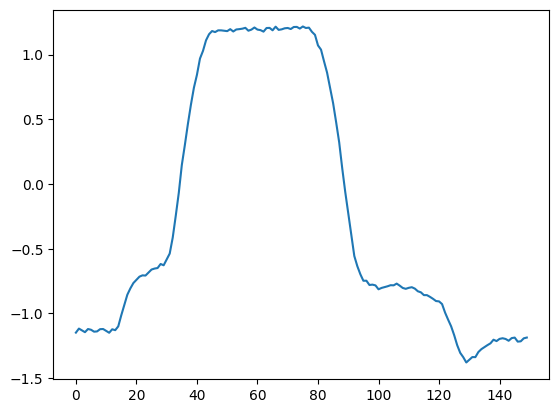

In [7]:
import matplotlib.pyplot as plt
plt.plot(batch["x"][0,0,:].numpy())

In [8]:
batch['y'].shape

torch.Size([24])

In [9]:
logger.info(f"Dataset splits, train: {len(train_dataset)}, valid: {len(valid_dataset)}, test: {len(test_dataset)}")

In [10]:
# Instantiate model
model = hydra.utils.instantiate(cfg.model.object) #.to(device)
n_params = count_parameters(model)
logger.info(f"Training: {cfg.name} (params: {n_params:,})".replace(",", " "))

In [11]:
# import numpy as np
# model_parameters = filter(lambda p: p.requires_grad, model.parameters())
# params = sum([np.prod(p.size()) for p in model_parameters])
# print(params)

In [12]:
# Load Pretrained Checkpoint (if exists)
if (cfg.pretrain_checkpoint is not None) and Path(cfg.pretrain_checkpoint).exists():
    mismatch_over_union_layers, mismatch_over_union_params = load_partial_state_dict(model, cfg.pretrain_checkpoint)
    logger.info(f"Loaded pre-trained model from {cfg.pretrain_checkpoint}: {1.0 - mismatch_over_union_layers:.2f} -- {1.0 - mismatch_over_union_params:.2f}")

In [13]:
    ##############################
    # Actual Task: Training Loop
    ##############################
    # Training loop 
results = train_model(model, cfg, train_loader, valid_loader, test_loader)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
You are using a CUDA device ('NVIDIA RTX A500 Laptop GPU') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
d:\DSME\Code\Repos\CEL\.venv\Lib\site-packages\lightning\pytorch\callbacks\model_checkpoint.py:654: Checkpoint directory D:\DSME\Code\Repos\CEL\data\models\GunPoint_InceptionTime10_tscHFNoiseWarp_xs_adamw_patient__2_ exists and is not empty.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name      | Type               | Params | Mode 
---------------------------------------------------------
0 | model     | InceptionTime      | 696 K  | train
1 | criterion | NLLLoss            | 0      | train
2 | train_acc | Mu

d:\DSME\Code\Repos\CEL\.venv\Lib\site-packages\lightning\pytorch\loops\fit_loop.py:298: The number of training batches (6) is smaller than the logging interval Trainer(log_every_n_steps=50). Set a lower value for log_every_n_steps if you want to see logs for the training epoch.


Epoch 50: 100%|██████████| 6/6 [00:00<00:00, 10.39it/s, v_num=0, train_acc_step=1.000, train_f1_step=1.000, train_loss_step=0.0372, val_acc=1.000, val_f1=1.000, val_loss=0.0134, train_acc_epoch=0.993, train_f1_epoch=0.993, train_loss_epoch=0.0307] 


Restoring states from the checkpoint path at data\models\GunPoint_InceptionTime10_tscHFNoiseWarp_xs_adamw_patient__2_\zero.ckpt
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Loaded model weights from the checkpoint at data\models\GunPoint_InceptionTime10_tscHFNoiseWarp_xs_adamw_patient__2_\zero.ckpt


Testing DataLoader 0: 100%|██████████| 1/1 [00:00<00:00,  5.15it/s]
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
       Test metric             DataLoader 0
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
        test_acc            0.4166666567325592
         test_f1            0.4166666567325592
        test_loss           0.7047298550605774
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────


Restoring states from the checkpoint path at D:\DSME\Code\Repos\CEL\data\models\GunPoint_InceptionTime10_tscHFNoiseWarp_xs_adamw_patient__2_\last.ckpt
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Loaded model weights from the checkpoint at D:\DSME\Code\Repos\CEL\data\models\GunPoint_InceptionTime10_tscHFNoiseWarp_xs_adamw_patient__2_\last.ckpt


Testing DataLoader 0: 100%|██████████| 1/1 [00:00<00:00,  5.15it/s]
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
       Test metric             DataLoader 0
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
        test_acc                    1.0
         test_f1                    1.0
        test_loss          0.015804631635546684
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────


Restoring states from the checkpoint path at D:\DSME\Code\Repos\CEL\data\models\GunPoint_InceptionTime10_tscHFNoiseWarp_xs_adamw_patient__2_\best.ckpt
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Loaded model weights from the checkpoint at D:\DSME\Code\Repos\CEL\data\models\GunPoint_InceptionTime10_tscHFNoiseWarp_xs_adamw_patient__2_\best.ckpt


Testing DataLoader 0: 100%|██████████| 1/1 [00:00<00:00,  5.32it/s]
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
       Test metric             DataLoader 0
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
        test_acc                    1.0
         test_f1                    1.0
        test_loss           0.01585552468895912
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────


In [14]:
##############################
# Saving Results
##############################
if int(os.environ.get("SLURM_PROCID", 0)) == 0:
    # Save test metrics
    with open(save_dir / "training_results.json", "w") as f:
        json.dump(results, f, indent=4)

    # Empty CUDA cache if GPU is available
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    # Perform garbage collection
    gc.collect()

print( results["last"]["test_loss"])

0.015804631635546684
